In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("../data/bronze/Entities.csv", index_col=0)

Limpieza general

In [3]:
df = df.drop(columns=["property_id","agency","agent","location_id","page_url"])

In [4]:
print(len(df))
df = df.drop_duplicates()
print(len(df))

168446
147957


Limpieza Variables:

Primera vuelta limpieza: 

Variable baths

In [5]:
df["baths"].value_counts()

baths
0      35572
3      29060
2      22449
4      17985
6      15362
5      14067
7       5151
1       4792
8       1970
10       839
9        688
12        10
11         5
13         3
14         3
403        1
Name: count, dtype: int64

In [6]:
df = df[df["baths"] < 7]

In [7]:
len(df)

139287

Variable bedrooms: 

In [8]:
df["bedrooms"].value_counts()

bedrooms
3     38996
2     26764
4     21181
5     19768
0     18135
6      8218
1      3925
7       904
8       631
9       326
10      308
11       80
12       21
14        7
15        7
16        4
28        3
25        3
13        2
18        1
21        1
68        1
27        1
Name: count, dtype: int64

In [9]:
df = df[df["bedrooms"]<7]
len(df)

136987

Variables bedroom - bathroom conjuntas: 

In [10]:
df.groupby("bedrooms")["baths"].value_counts().unstack(fill_value=0)

baths,0,1,2,3,4,5,6
bedrooms,,,,,,,
0,17817,74,89,61,31,27,36
1,530,2890,485,14,3,2,1
2,3679,1542,18415,2948,141,21,18
3,5519,226,2406,23719,6428,654,44
4,2874,40,795,1325,9966,5228,953
5,2532,8,153,572,811,7388,8304
6,1777,7,80,304,362,468,5220


In [11]:
df = df[~((df["bedrooms"] == 0) & (df["baths"] > 0))].reset_index(drop=True)

In [12]:
df = df[~((df["baths"] == 0) & (df["bedrooms"] > 1))].reset_index(drop=True)

In [13]:
n_antes = len(df)
df = df.query("not (bedrooms == 0 and baths == 0)").reset_index(drop=True)
print(f"Filas eliminadas: {n_antes - len(df)}")

Filas eliminadas: 17817


Variable city:

In [14]:
df["city"].value_counts()

city
Karachi       38185
Lahore        27453
Islamabad     22790
Rawalpindi    11754
Faisalabad     2289
Name: count, dtype: int64

Variable date_added: 

In [15]:
df["date_added"] = pd.to_datetime(df["date_added"])
df["date_added"].dtype

dtype('<M8[us]')

Variable location: 

In [16]:
df["location"].nunique()

1406

In [17]:
CENTROS = {
    "Lahore":     (31.582045, 74.329376),
    "Karachi":    (24.860966, 66.990501),
    "Islamabad":  (33.738045, 73.084488),
    "Rawalpindi": (33.626057, 73.071442),
    "Faisalabad": (31.418715, 73.079109),
}
R_TIERRA_KM = 6371.0088

lat_c = df["city"].map(lambda c: CENTROS[c][0])
lon_c = df["city"].map(lambda c: CENTROS[c][1])

lat1, lon1 = np.radians(df["latitude"]), np.radians(df["longitude"])
lat2, lon2 = np.radians(lat_c), np.radians(lon_c)

# Fórmula de Haversine (distancia en línea recta sobre la esfera, en km)
a = np.sin((lat1 - lat2) / 2) ** 2 + np.cos(lat2) * np.cos(lat1) * np.sin((lon1 - lon2) / 2) ** 2
df["dist_centro_km"] = (2 * R_TIERRA_KM * np.arcsin(np.sqrt(a))).round(2)

df.groupby("city")["dist_centro_km"].describe()

,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Faisalabad,2289.0,7.954688,82.148318,0.00,4.04,5.61,7.36,3932.06
Islamabad,22790.0,14.422144,54.921898,0.72,9.38,11.53,18.90,5404.75
Karachi,38185.0,15.453015,13.660381,0.30,8.86,12.23,18.10,942.89
Lahore,27453.0,16.098127,7.386394,0.32,11.92,15.30,19.05,268.65
Rawalpindi,11754.0,9.842999,37.558160,0.27,6.92,8.91,12.55,4046.89


In [18]:
n_antes = len(df)
df = df[df["dist_centro_km"] <= 100].reset_index(drop=True)
print(f"Filas eliminadas por coordenadas erróneas: {n_antes - len(df)}")

Filas eliminadas por coordenadas erróneas: 23


Variable price

In [19]:
PKR_TO_EUR_2019 = 1 / 179.61   # ≈ 0.005568, valutafx, 18/07/2019

df["price"] = (df["price"] * PKR_TO_EUR_2019).round(2)

Variable property type

In [20]:
df["property_type"].value_counts()

property_type
House            60483
Flat             26951
Upper Portion     8528
Lower Portion     5514
Room               494
Penthouse          270
Farm House         208
Name: count, dtype: int64

In [21]:
df[df["property_type"] == "Room"]

,property_type,price,location,city,province_name,latitude,longitude,baths,purpose,bedrooms,date_added,Total_Area,dist_centro_km
156,Room,44.54,Gulshan-e-Iqbal Town,Karachi,Sindh,24.898465,67.062500,1,For Rent,1,2019-07-18,26136.096,8.37
419,Room,278.38,DHA Defence,Karachi,Sindh,24.830406,67.053764,3,For Rent,3,2019-07-18,5445.020,7.23
675,Room,83.51,G-11,Islamabad,Islamabad Capital,33.663818,72.995260,1,For Rent,1,2019-06-27,4356.016,11.67
1278,Room,128.06,DHA Defence,Karachi,Sindh,24.834337,67.055397,1,For Rent,1,2019-07-18,19329.821,7.19
1557,Room,111.35,G-11,Islamabad,Islamabad Capital,33.669533,73.000073,0,For Rent,1,2019-07-17,4900.518,10.91
...,...,...,...,...,...,...,...,...,...,...,...,...,...
101232,Room,306.22,DHA Defence,Karachi,Sindh,24.782215,67.074537,1,For Rent,1,2019-07-17,5445.000,12.19
101569,Room,33.41,Dhoke Banaras Road,Rawalpindi,Punjab,33.592470,73.014950,0,For Rent,1,2019-07-17,272.251,6.43
101695,Room,178.16,DHA Defence,Karachi,Sindh,24.805045,67.064323,1,For Rent,1,2019-07-17,11979.044,9.70
101834,Room,445.41,DHA Defence,Karachi,Sindh,24.805045,67.064323,1,For Rent,1,2019-07-17,5445.000,9.70


In [22]:
mask = (df["bedrooms"] > 1) & (df["property_type"] == "Room")
print(f"Filas que cambian de Room a Flat: {mask.sum()}")

df.loc[mask, "property_type"] = "Flat"

Filas que cambian de Room a Flat: 64


Variable province_name

In [23]:
df["province_name"].value_counts()

province_name
Punjab               41488
Sindh                38181
Islamabad Capital    22779
Name: count, dtype: int64

In [24]:
df = pd.get_dummies(df, columns=["province_name"], prefix="prov", drop_first=True, dtype=int)

Variable purpose:

In [25]:
df["purpose"].value_counts()

purpose
For Sale    74032
For Rent    28416
Name: count, dtype: int64

In [26]:
df = df[df["purpose"] == "For Sale"]
df = df.drop(columns=["purpose"]).reset_index(drop=True)

In [27]:
df

,property_type,price,location,city,latitude,longitude,baths,bedrooms,date_added,Total_Area,dist_centro_km,prov_Punjab,prov_Sindh
0,Flat,55676.19,G-10,Islamabad,33.679890,73.012640,2,2,2019-02-04,1089.004,9.27,0,0
1,Flat,38416.57,E-11,Islamabad,33.700993,72.971492,3,3,2019-05-04,15246.056,11.23,0,0
2,House,91865.71,G-15,Islamabad,33.631486,72.926559,6,5,2019-07-17,2178.008,18.81,0,0
3,House,242191.41,Bani Gala,Islamabad,33.707573,73.151199,4,4,2019-04-05,10890.000,7.04,0,0
4,House,38973.33,DHA Defence,Islamabad,33.492591,73.301339,3,3,2019-07-10,2178.008,33.88,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
74027,Flat,28951.62,Bahria Town Karachi,Karachi,25.013015,67.314401,2,2,2019-07-18,11434.542,36.78,0,1
74028,Flat,41757.14,Bahria Town Karachi,Karachi,25.013015,67.314401,3,3,2019-07-18,2178.008,36.78,0,1
74029,House,48995.04,Bahria Town Karachi,Karachi,25.071948,67.338656,4,3,2019-07-18,2178.008,42.21,0,1
74030,House,77946.66,Bahria Town Karachi,Karachi,25.058062,67.306626,3,3,2019-07-18,2178.008,38.68,0,1


Variable Total_Area: 

In [28]:
df["Total_Area"] = (df["Total_Area"] * 0.09290304).round(2)

Segunda vuelta limpieza: 

Variable property_type

In [29]:
df = df[~((df["property_type"] == "Flat") & (df["Total_Area"] > 250))].reset_index(drop=True)

In [30]:
n_antes = len(df)
df = df[~((df["property_type"] == "House") & (df["Total_Area"] > 2500))].reset_index(drop=True)
print(f"Casas eliminadas: {n_antes - len(df)}")

Casas eliminadas: 2078


In [31]:
df["city"].value_counts()

city
Lahore        26067
Karachi       15647
Islamabad      6423
Rawalpindi     6028
Faisalabad     1541
Name: count, dtype: int64

Variables latitude y longitude: 

In [32]:
df = df.drop(columns=["latitude", "longitude"])

In [33]:
df

,property_type,price,location,city,baths,bedrooms,date_added,Total_Area,dist_centro_km,prov_Punjab,prov_Sindh
0,Flat,55676.19,G-10,Islamabad,2,2,2019-02-04,101.17,9.27,0,0
1,House,91865.71,G-15,Islamabad,6,5,2019-07-17,202.34,18.81,0,0
2,House,242191.41,Bani Gala,Islamabad,4,4,2019-04-05,1011.71,7.04,0,0
3,House,38973.33,DHA Defence,Islamabad,3,3,2019-07-10,202.34,33.88,0,0
4,Penthouse,222704.75,F-11,Islamabad,5,5,2019-06-27,505.86,11.01,0,0
...,...,...,...,...,...,...,...,...,...,...,...
55701,House,77946.66,Bahria Town Karachi,Karachi,5,4,2019-07-18,354.10,36.59,0,1
55702,Flat,41757.14,Bahria Town Karachi,Karachi,3,3,2019-07-18,202.34,36.78,0,1
55703,House,48995.04,Bahria Town Karachi,Karachi,4,3,2019-07-18,202.34,42.21,0,1
55704,House,77946.66,Bahria Town Karachi,Karachi,3,3,2019-07-18,202.34,38.68,0,1


## Tercera vuelta de limpieza: superficie y precio

Tras las dos vueltas anteriores todavía quedan valores que no tienen sentido. Los buscamos y los tratamos **antes** de separar train y test, porque son reglas fijas (no aprenden de los datos).

Cada decisión sigue el esquema *hallazgo → acción → justificación → filas eliminadas*.

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

n_inicial_3v = len(df)
print(f"Filas de partida: {n_inicial_3v}")

df.groupby("property_type")["Total_Area"].agg(["count", "min", "median", "max"]).round(1)

Filas de partida: 55706


,count,min,median,max
property_type,,,,
Farm House,183,75.9,4046.9,128993.6
Flat,3108,25.3,101.2,227.6
House,49923,0.0,252.9,2478.7
Lower Portion,670,25.3,910.6,14164.0
Penthouse,202,75.9,1340.5,8599.6
Room,8,25.3,366.8,809.4
Upper Portion,1612,50.6,1087.6,56656.0


### Superficie (`Total_Area`)

**Hallazgo.** Los filtros de las vueltas anteriores solo cubren `Flat` (≤ 250 m²) y `House` (≤ 2.500 m²). El resto de tipos conserva superficies imposibles: la tabla muestra un máximo de casi 129.000 m² y, en el gráfico, `Upper Portion`, `Lower Portion` y `Penthouse` llegan a decenas de miles de m² cuando son una planta de una casa o un piso.

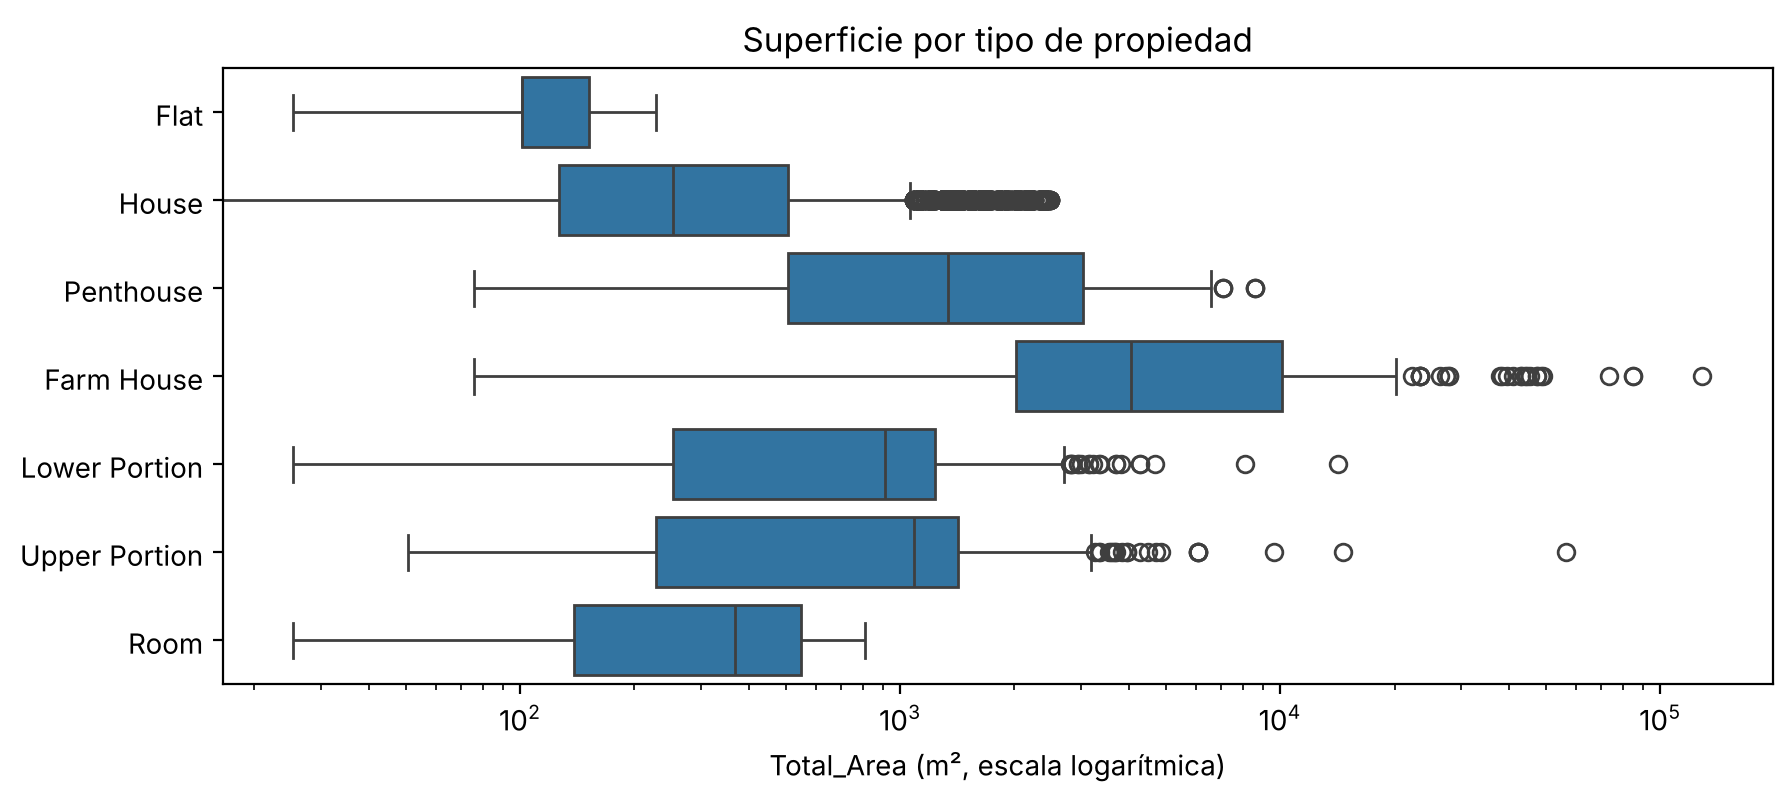

In [35]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=df, x="Total_Area", y="property_type", ax=ax)
ax.set_xscale("log")
ax.set_xlabel("Total_Area (m², escala logarítmica)")
ax.set_ylabel("")
ax.set_title("Superficie por tipo de propiedad")
plt.show()

**Decisión 1: superficie mínima.** Un anuncio con menos de 10 m² no es una vivienda real. Miramos cuáles son.

In [36]:
menores = df[df["Total_Area"] < 10]
print(f"Anuncios con Total_Area < 10 m²: {len(menores)}")
menores[["property_type", "price", "Total_Area", "bedrooms", "city"]]

Anuncios con Total_Area < 10 m²: 7


,property_type,price,Total_Area,bedrooms,city
12636,House,24497.52,0.0,2,Karachi
15577,House,69595.23,0.0,5,Lahore
41789,House,100217.14,0.0,3,Lahore
45524,House,91865.71,0.0,5,Islamabad
46350,House,12248.76,0.0,2,Lahore
53863,House,25054.28,0.0,2,Lahore
55321,House,27838.09,0.0,5,Rawalpindi


Son anuncios de casas con 2 a 5 habitaciones y **0 m²**: el cero es un dato que falta, no una superficie real. Son pocos (7 filas, el 0,01 %) y no hay forma fiable de recuperar el valor, así que **se eliminan**.

In [37]:
n_antes = len(df)
df = df[df["Total_Area"] >= 10].reset_index(drop=True)
print(f"Filas eliminadas por superficie < 10 m²: {n_antes - len(df)}")

Filas eliminadas por superficie < 10 m²: 7


**Decisión 2: superficie máxima en el resto de tipos.** Una planta de una casa (`Upper Portion`, `Lower Portion`), un `Penthouse` o una `Room` no puede ser mayor que una casa entera. Aplicamos el mismo límite que a las casas (2.500 m²).

`Farm House` **no se toca**: una granja puede ser legítimamente muy grande (la mediana es de unos 4.000 m²), así que sus valores altos son atípicos reales, no errores.

In [38]:
TIPOS_PARCIALES = ["Upper Portion", "Lower Portion", "Penthouse", "Room"]
mask = df["property_type"].isin(TIPOS_PARCIALES) & (df["Total_Area"] > 2500)
print(f"Filas que superan 2.500 m² (tipos parciales): {mask.sum()}")
print(df[mask]["property_type"].value_counts())

df = df[~mask].reset_index(drop=True)

Filas que superan 2.500 m² (tipos parciales): 157
property_type
Upper Portion    67
Penthouse        62
Lower Portion    28
Name: count, dtype: int64


### Precio (`price`)

**Hallazgo.** El precio tiene una asimetría muy fuerte y, en el extremo bajo, hay anuncios con precios de unos pocos euros, que no corresponden a una venta real (probablemente alquileres o errores de escritura).

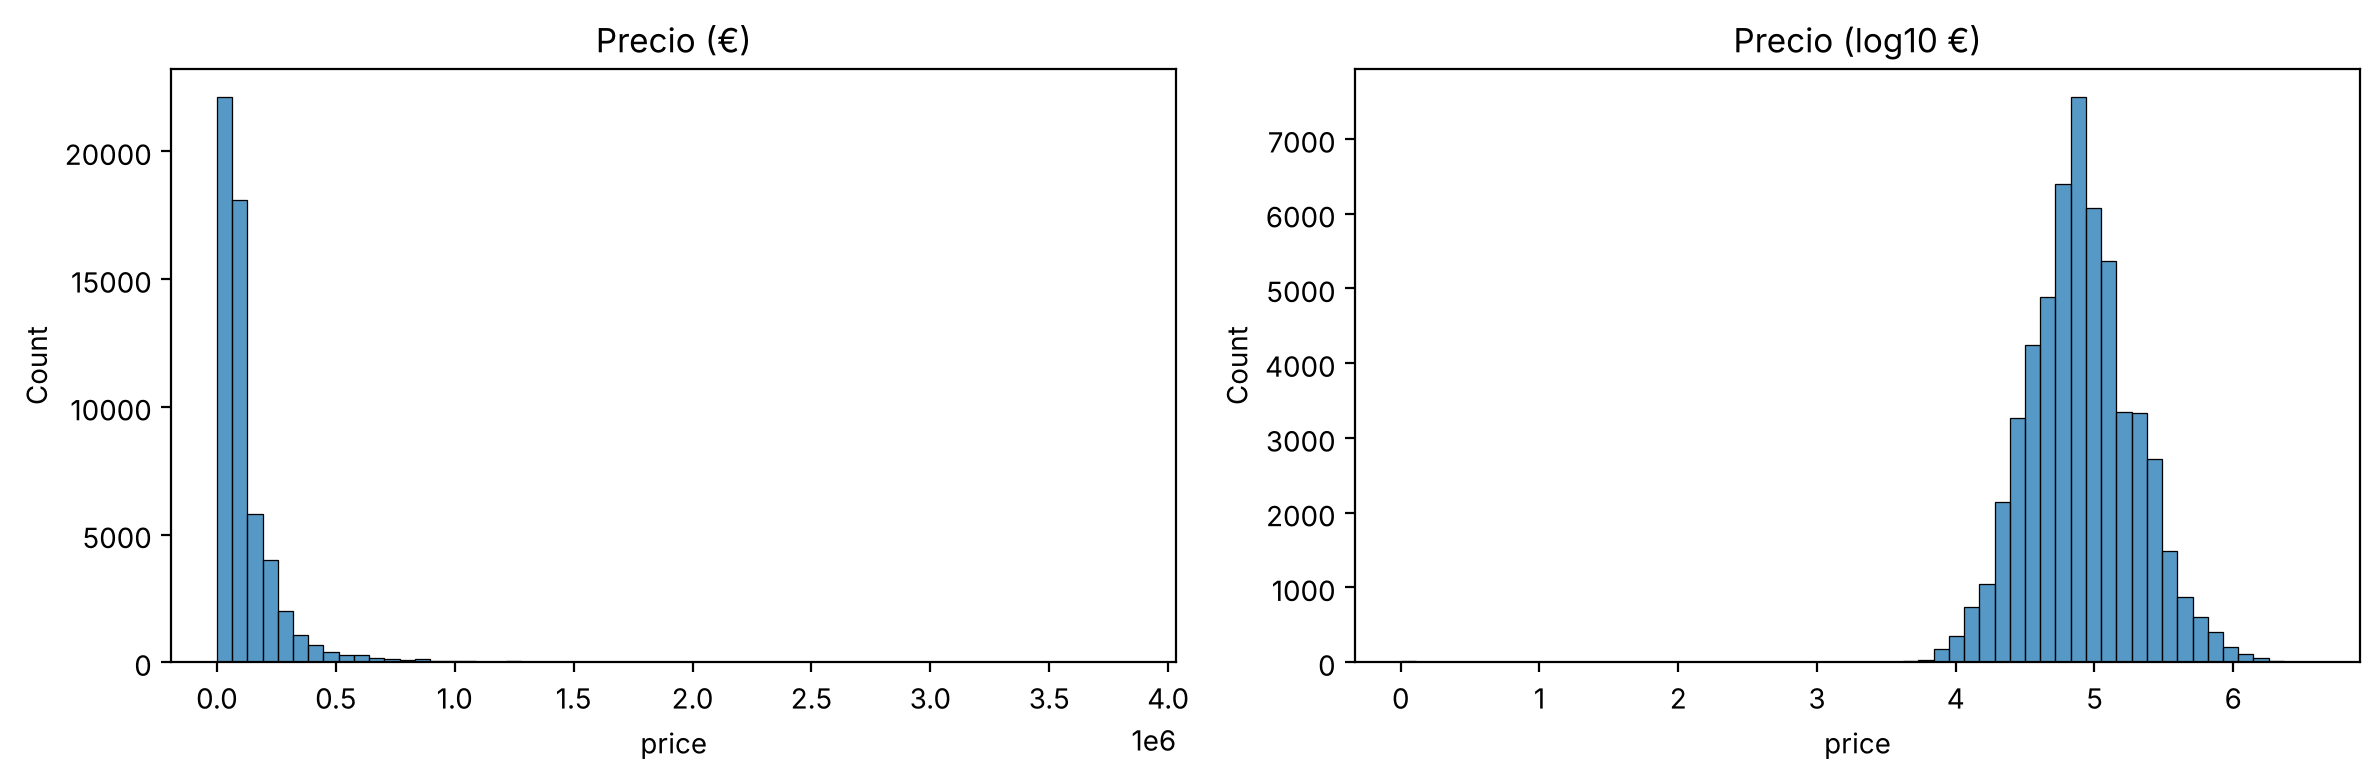

Precios por debajo de 1.000 €: 57


property_type
Farm House        1
Flat              2
House            30
Lower Portion    10
Room              2
Upper Portion    12
dtype: int64

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], bins=60, ax=axes[0])
axes[0].set_title("Precio (€)")
sns.histplot(np.log10(df["price"].clip(lower=1)), bins=60, ax=axes[1])
axes[1].set_title("Precio (log10 €)")
plt.tight_layout()
plt.show()

print("Precios por debajo de 1.000 €:", (df["price"] < 1000).sum())
df[df["price"] < 1000].groupby("property_type").size()

**Decisión 3: precio mínimo.** Por debajo de 1.000 € (unas 180.000 rupias) no hay ninguna casa, piso ni piso parcial a la venta con sentido. Son pocos anuncios (0,1 %) y no se pueden corregir, así que **se eliminan**.

In [40]:
n_antes = len(df)
df = df[df["price"] >= 1000].reset_index(drop=True)
print(f"Filas eliminadas por precio < 1.000 €: {n_antes - len(df)}")

Filas eliminadas por precio < 1.000 €: 57


**Decisión 4: precios altos, se conservan.** Calculamos cuántos anuncios quedan fuera del criterio IQR y qué efecto tiene un logaritmo.

In [41]:
q1, q3 = df["price"].quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
n_altos = (df["price"] > limite).sum()
print(f"Límite superior IQR: {limite:,.0f} € -> {n_altos} anuncios ({n_altos / len(df):.1%})")
print(f"Asimetría de price:      {df['price'].skew():.2f}")
print(f"Asimetría de log(price): {np.log(df['price']).skew():.2f}")

Límite superior IQR: 281,165 € -> 4533 anuncios (8.2%)
Asimetría de price:      4.82
Asimetría de log(price): 0.19


Hay un grupo grande de anuncios por encima del límite IQR, pero **no se eliminan**: son propiedades caras de verdad (casas grandes en zonas como DHA o Bani Gala), no errores. Quitarlos haría que el modelo no supiera estimar el segmento alto.

**Acción:** mantenerlos y tratar la asimetría con `log(price)` como variable objetivo (se decide en el EDA y en la fase de modelado).

In [42]:
print(f"Filas de partida de esta vuelta: {n_inicial_3v}")
print(f"Filas finales:                     {len(df)}")
print(f"Filas eliminadas en total:         {n_inicial_3v - len(df)}")
df.shape

Filas de partida de esta vuelta: 55706
Filas finales:                     55485
Filas eliminadas en total:         221


(55485, 11)

### Resumen de la tercera vuelta

| Hallazgo | Acción | Justificación | Filas eliminadas |
|---|---|---|---|
| `Total_Area` < 10 m² (en realidad 0 m²) | Eliminar | El cero es un dato ausente, no recuperable | 7 |
| `Upper Portion`, `Lower Portion`, `Penthouse` y `Room` con más de 2.500 m² | Eliminar | Una parte de una casa no puede superar a una casa entera (mismo límite que `House`) | 157 |
| `Farm House` con superficies muy grandes | Conservar | Son valores atípicos reales | 0 |
| `price` < 1.000 € | Eliminar | No corresponde a una venta real y no se puede corregir | 57 |
| `price` por encima del límite IQR | Conservar | Propiedades caras reales; se trata con `log(price)` | 0 |
